# 20 · CTR线性基线与特征工程

第18章保留总览；本章单独深入一个问题。正式200k实验不覆盖，教学训练使用独立共享记录。

## 先预测：常量先验和个性化概率有什么区别？

CTR学习输入是曝光特征，输出是点击概率。常量模型p等于train点击率，没有区分能力，但在低点击率任务上可以有很小ECE。逻辑回归将特征的加性分数映射到(0,1)；对匿名类别做onehot是为了避免把哈希值的大小当成有序距离。

本章固定40k前缀、同一分区、C=1、优化轮数和数值预处理，只改变是否加入26个类别字段。所有成绩来自select；正式audit不读入选型。

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from reclab.ads import latest, load_data, split_groups, NUM, CAT, FEATURES
from reclab.paths import ARTIFACTS
from reclab.probability import evaluate
preview=ARTIFACTS/'notebook-previews';preview.mkdir(parents=True,exist_ok=True)
frame,_=load_data(40000);masks,_=split_groups(frame);y=frame.label.to_numpy()
prior=np.full(int(masks['select'].sum()),y[masks['train']].mean())
print('Input:',frame[FEATURES].shape,'label:',y.shape)
print('Train prior, select evaluation:',{k:v for k,v in evaluate(y[masks['select']],prior).items() if k!='reliability'})

Input: (40000, 39) label: (40000,)
Train prior, select evaluation: {'n': 6006, 'positives': 194, 'click_rate': 0.032301032301032304, 'mean_probability': 0.030739193606974205, 'auc': 0.5, 'logloss': 0.14269226135422958, 'brier': 0.03126011495342623, 'ece': 0.0015618386940580986}


## 输入如何变成设计矩阵

数值做保符号log1p，保留负值方向、压缩长尾；train中位数填补、缺失指示和标准化随后进行。类别列采用最多128类别的稀疏onehot，罕见与未见类别由同一编码器处理。最终维度不是39，实际输出应检查shape和稀疏存储。

下面单独观察数值设计矩阵。先猜增加缺失指示会多几列；有些列在train中从不缺失，因此并非固定多13列。

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer,StandardScaler
from sklearn.impute import SimpleImputer
from reclab.ads import signed_log
numeric=make_pipeline(FunctionTransformer(signed_log),SimpleImputer(strategy='median',add_indicator=True),StandardScaler())
z=numeric.fit_transform(frame.loc[masks['train'],NUM])
print('Raw numeric:',(int(masks['train'].sum()),13),'transformed:',z.shape)
assert np.isfinite(z).all()
print('Scale learned on train; select is transform-only:',numeric.transform(frame.loc[masks['select'],NUM]).shape)

Raw numeric: (22024, 13) transformed: (22024, 24)
Scale learned on train; select is transform-only: (6006, 24)


## 真正运行：只增加类别特征

下面调用共享教学训练器，两组分别拟合；每次执行都会新建ads实验记录，保存本地系数与select预测，失败也保留。它不替换200k正式模型。预计只需数秒，具体以本机墙钟为准。

先写下你对AUC和logloss方向的预期，再执行。即使加入类别提升，本轮也只能解释成这段前缀与这个特征预算中的结果。

In [3]:
from reclab.ads_teaching import workshop
run_id,comparison=workshop('linear_features')
print('Shared workshop run:',run_id,'shapes:',comparison['shapes'])
table=pd.DataFrame([{'method':r['method'],'dimension':r['features'],'seconds':r['fit_seconds'],'iterations':r['iterations'],**{k:r['select'][k] for k in ['auc','logloss','brier','ece']}} for r in comparison['rows']])
display(table)
assert all(r['iterations']<300 for r in comparison['rows'])

Shared workshop run: 20261030T130907-22ac6037 shapes: {'raw': [40000, 39], 'train': 22024, 'select': 6006}


,method,dimension,seconds,iterations,auc,logloss,brier,ece
0,numeric_only,24,0.059206,14,0.707051,0.134451,0.030668,0.001666
1,numeric+categorical,2470,0.814952,108,0.721102,0.135359,0.031107,0.008736


## 解释系数时要带着单位

线性模型对log-odds加性建模；标准化数值系数对应一个训练标准差，onehot系数对应编码类别条件下的相对偏移。缺失指示与类别编码让“某字段系数大”并不等于“这个真实因素导致点击”。匿名数据更不能据此给用户画像。

保存的NPZ在本机可检查系数shape、非零数和概率范围；这里仅显示聚合范数，权重不进入Git。

numeric_only coef shape: (1, 24) L2 norm: 0.5670679800150403 probability range: 0.0010747912904707244 0.24311326416319087
numeric+categorical coef shape: (1, 2470) L2 norm: 16.457663076525826 probability range: 4.10356476796253e-05 0.7478277943321489


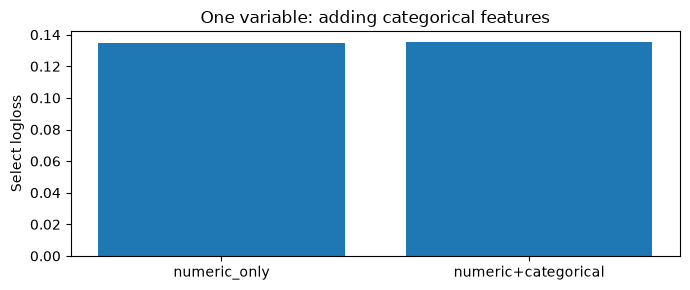

In [4]:
folder=ARTIFACTS/'experiments/ads'/run_id
for row in comparison['rows']:
    weights=np.load(folder/(row['method']+'.npz'),allow_pickle=False)
    print(row['method'],'coef shape:',weights['coef'].shape,'L2 norm:',float(np.linalg.norm(weights['coef'])),
          'probability range:',float(weights['select_probability'].min()),float(weights['select_probability'].max()))
fig,ax=plt.subplots(figsize=(7,3));ax.bar(table.method,table.logloss)
ax.set(ylabel='Select logloss',title='One variable: adding categorical features');fig.tight_layout();fig.savefig(preview/'20_linear.png',dpi=130);plt.show()

## 单变量练习与解释

先保持特征不变，仅在临时模型中修改C，预测强正则化会如何改变概率分布。下面的损失压力测试只改变置信度，不把它称为重新训练的模型。把p缩向train先验，区分度可能保持，概率损失仍可改变。

解释：AUC相同不能推出logloss相同；只有一种指标改善也不能直接推出线上收益。真正的C对照应通过共享训练器扩展配置并使用select，最终保留新的独立audit。

In [5]:
saved=np.load(folder/'numeric+categorical.npz',allow_pickle=False)
p=saved['select_probability'];rate=float(y[masks['train']].mean())
alpha=.5  # Exercise: change only this shrinkage factor.
shrunk=alpha*p+(1-alpha)*rate
for name,prob in [('original',p),('shrink_to_prior',shrunk)]:
    r=evaluate(y[masks['select']],prob);print(name,{k:r[k] for k in ['auc','logloss','brier']})
print('This is a controlled probability transform, not a retrained regularization experiment.')

original {'auc': 0.7211022697440772, 'logloss': 0.13535924760121054, 'brier': 0.031106683422217875}
shrink_to_prior {'auc': 0.7211022697440772, 'logloss': 0.13363860416569606, 'brier': 0.030527528460338932}
This is a controlled probability transform, not a retrained regularization experiment.
